# 01. Data Exploration and Cleaning

## Objective

In this notebook, I explore the SUIM underwater image dataset and prepare it for semantic segmentation.

Before training my U-Net model, I need to understand the dataset, examine the segmentation masks, and identify data quality problems that could affect model performance.

I will investigate image dimensions, mask colors, duplicate images, and class distributions. I will then document my cleaning decisions and create reproducible training and validation splits.

The official SUIM test set will remain separate throughout the experiment. **I will not use test labels to select a model or tune preprocessing.**

**Research question:** Does underwater image enhancement improve CNN segmentation, or only the visual appearance of underwater images?

## 1. Setup and reproducibility

The decoder uses the official SUIM class order. The three binary RGB bits use channel values 0 and 255. In class-ID order, the codes are **BW, HD, PF, WR, RO, RI, FV, SR**. The setup cell checks all eight RGB-to-ID conversions. [Official SUIM dataset documentation](https://irvlab.cs.umn.edu/resources/suim-dataset)

In [2]:
from pathlib import Path
from collections import Counter, defaultdict
import hashlib
import os
import platform
import random
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image

SEED = 42
VAL_FRACTION = 0.15
AGREE_MIN = 0.90
random.seed(SEED)
np.random.seed(SEED)

PROJECT_ROOT = Path(os.environ.get("SUIM_PROJECT_ROOT", Path.cwd())).resolve()
if "SUIM_PROJECT_ROOT" not in os.environ:
    PROJECT_ROOT = next(
        (root for root in (PROJECT_ROOT, *PROJECT_ROOT.parents) if (root / "data" / "SUIM").is_dir()),
        PROJECT_ROOT,
    )
DATA_ROOT = PROJECT_ROOT / "data" / "SUIM"
RESULTS = Path(os.environ.get("SUIM_RESULTS_DIR", PROJECT_ROOT / "results")).resolve()
FIG_DIR = RESULTS / "figures" / "notebook_01"
TABLE_DIR = RESULTS / "tables" / "notebook_01"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["Water/background", "Diver", "Plant", "Wreck", "Robot", "Reef", "Fish", "Sea floor"]
PALETTE = np.array([[r, g, b] for r in (0, 255) for g in (0, 255) for b in (0, 255)], dtype=np.uint8)
# Class ID = 4*r + 2*g + b, where r, g, b are the binary channel bits.
CLASS_CODES = ["BW", "HD", "PF", "WR", "RO", "RI", "FV", "SR"]

def save_fig(name):
    plt.savefig(FIG_DIR / name, dpi=170, bbox_inches="tight")

def save_table(df, name):
    df.to_csv(TABLE_DIR / name, index=False)
    return df

def file_hash(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def rgb_to_ids(rgb):
    bits = (rgb > 127).astype(np.uint8)
    return (4 * bits[..., 0] + 2 * bits[..., 1] + bits[..., 2]).astype(np.uint8)

def paths_for(split):
    folder = DATA_ROOT / ("TEST" if split == "test" else "train_val")
    return folder / "images", folder / "masks"

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATA_ROOT.exists())
print("Python:", sys.version.split()[0], "| OS:", platform.platform())
print("NumPy:", np.__version__, "| pandas:", pd.__version__, "| Pillow:", Image.__version__)
assert DATA_ROOT.exists(), "SUIM data not found. Check the project root and data/SUIM folder."
# Check the decoder against the published RGB code for each class ID.
official_rgb = np.array([
    [0, 0, 0], [0, 0, 255], [0, 255, 0], [0, 255, 255],
    [255, 0, 0], [255, 0, 255], [255, 255, 0], [255, 255, 255],
], dtype=np.uint8)
np.testing.assert_array_equal(PALETTE, official_rgb)
np.testing.assert_array_equal(rgb_to_ids(official_rgb), np.arange(len(CLASS_NAMES)))
display(save_table(pd.DataFrame({
    "class_id": range(len(CLASS_NAMES)),
    "code": CLASS_CODES,
    "class_name": CLASS_NAMES,
    "rgb": [tuple(color) for color in official_rgb.tolist()],
}), "suim_class_mapping.csv"))


Project root: C:\Users\sabin\underwater-robotic-segmentation
Dataset exists: True
Python: 3.12.16 | OS: Windows-11-10.0.26200-SP0
NumPy: 2.5.4 | pandas: 3.1.1 | Pillow: 13.0.0


,class_id,code,class_name,rgb
0,0,BW,Water/background,"(0, 0, 0)"
1,1,HD,Diver,"(0, 0, 255)"
2,2,PF,Plant,"(0, 255, 0)"
3,3,WR,Wreck,"(0, 255, 255)"
4,4,RO,Robot,"(255, 0, 0)"
5,5,RI,Reef,"(255, 0, 255)"
6,6,FV,Fish,"(255, 255, 0)"
7,7,SR,Sea floor,"(255, 255, 255)"


## 2. Inventory and image-mask pairing

I need to establish how many files exist and whether each image has a corresponding mask. A missing or incorrectly paired mask would make supervised training unreliable. I identify pairs by filename stem, without changing the original files.

In [3]:
def inventory(split):
    image_dir, mask_dir = paths_for(split)
    images = {p.stem: p for p in image_dir.glob("*.jpg")}
    masks = {p.stem: p for p in mask_dir.glob("*.bmp")}
    paired = sorted(images.keys() & masks.keys())
    return images, masks, paired, sorted(images.keys() - masks.keys()), sorted(masks.keys() - images.keys())

inventories = {split: inventory(split) for split in ("train", "test")}
rows = []
for split, (images, masks, paired, no_mask, no_image) in inventories.items():
    rows.append(dict(split=split, images=len(images), masks=len(masks), paired=len(paired),
                     images_without_masks=len(no_mask), masks_without_images=len(no_image)))
inventory_df = save_table(pd.DataFrame(rows), "inventory.csv")
display(inventory_df)
for split, (_, _, _, no_mask, no_image) in inventories.items():
    print(split, "images without masks:", no_mask[:10], "| masks without images:", no_image[:10])

,split,images,masks,paired,images_without_masks,masks_without_images
0,train,1525,1525,1525,0,0
1,test,110,110,110,0,0


train images without masks: [] | masks without images: []
test images without masks: [] | masks without images: []



### Findings and Interpretation

The SUIM dataset contains 1,525 image-mask pairs in the training and validation directory and 110 pairs in the official test directory. All images have corresponding segmentation masks, with no missing or unmatched files.

This confirms that the dataset is complete in terms of file pairing. However, having a corresponding mask does not necessarily mean the annotation is correct. I therefore need to investigate image dimensions, mask colors, and duplicate samples before preparing the training data.

The official test set will remain separate throughout the experiment.


## 3. Inspect representative images and segmentation masks

SUIM uses eight semantic classes. Each mask color represents a class, so I must treat masks as labels rather than ordinary photographs. I inspect examples before applying any resizing or cleaning.

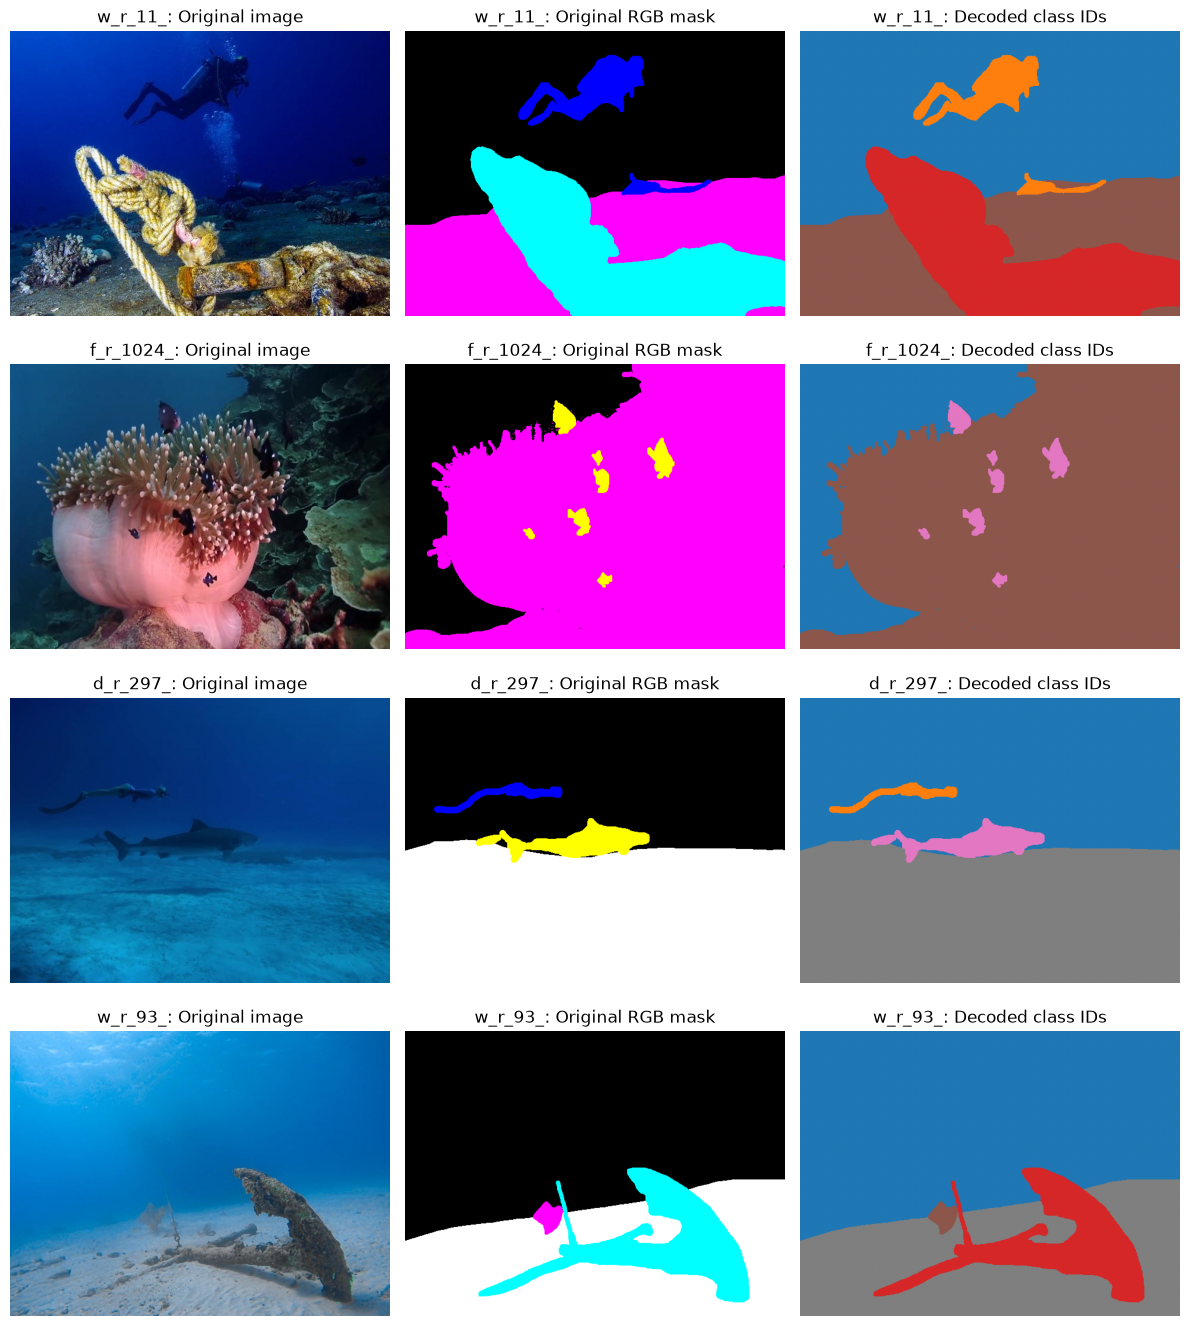

Palette (class ID, RGB): [(0, [0, 0, 0]), (1, [0, 0, 255]), (2, [0, 255, 0]), (3, [0, 255, 255]), (4, [255, 0, 0]), (5, [255, 0, 255]), (6, [255, 255, 0]), (7, [255, 255, 255])]


In [4]:
train_images, train_masks, train_stems, _, _ = inventories["train"]
assert train_stems, "No paired training files were found."
examples = random.Random(SEED).sample(train_stems, min(4, len(train_stems)))
fig, axes = plt.subplots(len(examples), 3, figsize=(12, 3.4 * len(examples)), squeeze=False)
for row, stem in enumerate(examples):
    with Image.open(train_images[stem]) as im: image = np.asarray(im.convert("RGB"))
    with Image.open(train_masks[stem]) as im: mask = np.asarray(im.convert("RGB"))
    axes[row, 0].imshow(image)
    axes[row, 1].imshow(mask)
    axes[row, 2].imshow(rgb_to_ids(mask), cmap="tab10", vmin=0, vmax=9)
    for col, title in enumerate(("Original image", "Original RGB mask", "Decoded class IDs")):
        axes[row, col].set_title(f"{stem}: {title}")
        axes[row, col].axis("off")
plt.tight_layout()
save_fig("sample_images_masks.png")
plt.show()
print("Palette (class ID, RGB):", list(enumerate(PALETTE.tolist())))


### Findings and Interpretation

The sample visualizations show the relationship between the original underwater images and their corresponding segmentation masks.

SUIM defines eight semantic classes, including water, diver, plant, wreck, robot, reef, fish, and sea floor. The RGB mask colors are converted into numerical class IDs ranging from 0 to 7, which will serve as the target labels for the U-Net model.

This inspection confirms that the images and masks can be loaded and visualized using the expected encoding. However, visual inspection of a few examples is not sufficient to establish annotation quality across the dataset. I will examine the full dataset for potential inconsistencies.


## 4. Check image dimensions and mismatched masks

Image and mask pixels must line up for segmentation. If their dimensions differ, a naive resize can hide the problem while preserving incorrect labels. I measure mismatches before deciding which samples to exclude.

In [5]:
records = []
for split in ("train", "test"):
    images, masks, paired, _, _ = inventories[split]
    for stem in paired:
        with Image.open(images[stem]) as im: iw, ih = im.size
        with Image.open(masks[stem]) as im: mw, mh = im.size
        records.append(dict(split=split, stem=stem, image_width=iw, image_height=ih,
                            mask_width=mw, mask_height=mh, width_difference=mw-iw,
                            height_difference=mh-ih, size_match=(iw == mw and ih == mh)))
dimensions = save_table(pd.DataFrame(records), "dimensions.csv")
display(dimensions.groupby("split")["size_match"].agg(total="count", matches="sum"))
mismatches = dimensions.loc[~dimensions.size_match].copy()
display(mismatches.head(12))
print("Mismatch counts:", mismatches.groupby("split").size().to_dict())
print("Common dimension differences:")
display(mismatches.groupby(["split", "width_difference", "height_difference"]).size().reset_index(name="count").sort_values("count", ascending=False).head(12))

,total,matches
split,,
test,110,110
train,1525,1488


,split,stem,image_width,image_height,mask_width,mask_height,width_difference,height_difference,size_match
254,train,f_r_1058_,590,375,590,430,0,55,False
262,train,f_r_1068_,590,375,590,430,0,55,False
263,train,f_r_1069_,590,375,590,430,0,55,False
264,train,f_r_1070_,590,375,590,430,0,55,False
308,train,f_r_1133_,590,375,590,430,0,55,False
313,train,f_r_1142_,590,375,590,430,0,55,False
318,train,f_r_1151_,590,375,590,430,0,55,False
321,train,f_r_1154_,590,375,590,430,0,55,False
359,train,f_r_1214_,590,375,590,430,0,55,False
371,train,f_r_1233_,590,375,590,430,0,55,False


Mismatch counts: {'train': 37}
Common dimension differences:


,split,width_difference,height_difference,count
0,train,0,55,37


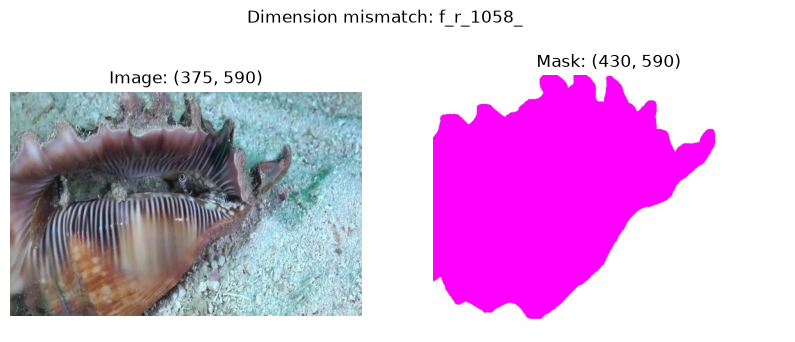

In [6]:
train_bad_size = mismatches.loc[mismatches.split == "train", "stem"].tolist()
if train_bad_size:
    stem = train_bad_size[0]
    with Image.open(train_images[stem]) as im: image = np.asarray(im.convert("RGB"))
    with Image.open(train_masks[stem]) as im: mask = np.asarray(im.convert("RGB"))
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(image); ax[0].set_title(f"Image: {image.shape[:2]}")
    ax[1].imshow(mask); ax[1].set_title(f"Mask: {mask.shape[:2]}")
    for a in ax: a.axis("off")
    fig.suptitle(f"Dimension mismatch: {stem}")
    save_fig("dimension_mismatch_example.png"); plt.show()
else:
    print("No training dimension mismatches detected.")


### Findings and Interpretation

The dimension analysis identified **37 image-mask pairs with mismatched dimensions** in the training and validation dataset. All 37 masks were 55 pixels taller than their corresponding images, while their widths remained the same.

For example, one image measured 590 × 375 pixels, while its segmentation mask measured 590 × 430 pixels.

This matters because semantic segmentation depends on accurate alignment between image pixels and their corresponding labels. When dimensions differ, the annotations may no longer describe the correct pixel locations.

Although resizing could make the image and mask dimensions identical, it would not guarantee that their contents are correctly aligned.

I therefore exclude these 37 samples from the training pool rather than introduce potentially unreliable annotations. All 110 official test image-mask pairs had matching dimensions.


## 5. Validate the mask color palette

The existing decoder thresholds RGB values at 128. That works for valid 0/255 mask colors, but **invalid RGB values could be silently mapped to a class**. I therefore inspect the original RGB values first and count how many pixels are outside the expected palette. I will not repair questionable labels without evidence.

In [7]:
palette_rows = []
invalid_examples = []
for split in ("train", "test"):
    _, masks, paired, _, _ = inventories[split]
    for stem in paired:
        with Image.open(masks[stem]) as im: rgb = np.asarray(im.convert("RGB"))
        valid = np.isin(rgb, (0, 255)).all(axis=2)
        invalid_count = int((~valid).sum())
        palette_rows.append(dict(split=split, stem=stem, pixels=int(valid.size),
                                 invalid_pixels=invalid_count, invalid_fraction=invalid_count/valid.size,
                                 palette_valid=invalid_count == 0))
        if invalid_count and len(invalid_examples) < 8:
            unique, counts = np.unique(rgb[~valid].reshape(-1, 3), axis=0, return_counts=True)
            order = np.argsort(counts)[::-1][:5]
            invalid_examples.append((split, stem, [(unique[i].tolist(), int(counts[i])) for i in order]))
palette_df = save_table(pd.DataFrame(palette_rows), "mask_palette_audit.csv")
display(palette_df.groupby("split").agg(masks=("stem", "count"), invalid_masks=("palette_valid", lambda x: int((~x).sum())), invalid_pixels=("invalid_pixels", "sum")))
print("Examples of invalid RGB colors:")
for example in invalid_examples: print(example)

,masks,invalid_masks,invalid_pixels
split,,,
test,110,0,0
train,1525,85,10095731


Examples of invalid RGB colors:
('train', 'd_r_112_', [([254, 0, 0], 8966), ([0, 1, 0], 2781), ([1, 0, 0], 2040), ([0, 0, 2], 1661), ([253, 1, 0], 1181)])
('train', 'd_r_135_', [([255, 0, 254], 189496), ([0, 0, 254], 4891), ([255, 0, 252], 1345), ([0, 1, 0], 998), ([254, 0, 0], 836)])
('train', 'd_r_174_', [([0, 0, 254], 92260), ([254, 0, 0], 44588), ([0, 1, 0], 7115), ([1, 0, 0], 5435), ([0, 0, 2], 5256)])
('train', 'd_r_179_', [([254, 0, 0], 48050), ([0, 0, 254], 37608), ([0, 1, 0], 3185), ([0, 1, 252], 2468), ([1, 0, 0], 2378)])
('train', 'd_r_189_', [([254, 0, 0], 95724), ([255, 254, 255], 3278), ([253, 1, 0], 3209), ([254, 255, 255], 2686), ([255, 255, 253], 2203)])
('train', 'd_r_20_', [([254, 0, 0], 130932), ([0, 0, 254], 48740), ([0, 1, 0], 5281), ([1, 0, 0], 4118), ([0, 0, 2], 3709)])
('train', 'd_r_270_', [([255, 0, 254], 179736), ([0, 0, 254], 4089), ([0, 1, 0], 1872), ([1, 0, 0], 1558), ([0, 0, 2], 1313)])
('train', 'd_r_273_', [([255, 0, 254], 137871), ([0, 0, 254], 20294)

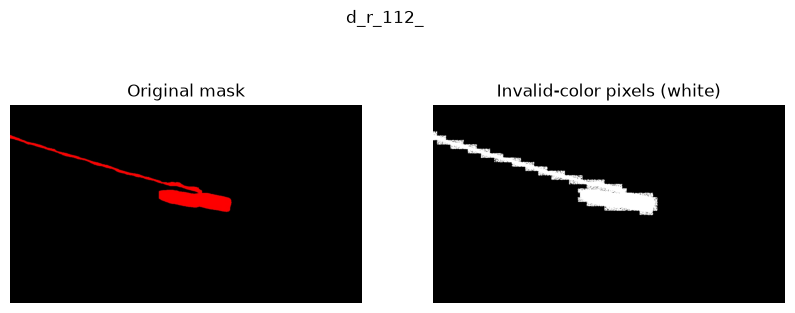

In [8]:
bad_palette_stems = palette_df.loc[(palette_df.split == "train") & (~palette_df.palette_valid), "stem"].tolist()
if bad_palette_stems:
    stem = bad_palette_stems[0]
    with Image.open(train_masks[stem]) as im: rgb = np.asarray(im.convert("RGB"))
    valid = np.isin(rgb, (0, 255)).all(axis=2)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].imshow(rgb); ax[0].set_title("Original mask")
    ax[1].imshow(~valid, cmap="gray"); ax[1].set_title("Invalid-color pixels (white)")
    for a in ax: a.axis("off")
    fig.suptitle(stem); save_fig("invalid_mask_colors.png"); plt.show()
else:
    print("No invalid colors in training masks.")


### Findings and Interpretation

The mask color analysis identified **85 training masks containing RGB values outside the expected SUIM palette**. Across these masks, 10,095,731 pixels contained off-palette values. No invalid colors were detected in the official test masks.

Some unexpected values were very close to valid class colors. For example, `(254, 0, 0)` appeared instead of `(255, 0, 0)`.

These differences may result from image processing or annotation inconsistencies, but their exact cause has not been established.

The existing class decoder uses a threshold to convert RGB values into class IDs. Although this allows near-valid colors to be assigned to classes, it can also hide inconsistencies in the original annotations.

For this experiment, I use a conservative cleaning strategy and exclude masks containing invalid palette values rather than automatically correcting them.

Of the 85 affected masks, 48 were assigned invalid colors as their primary exclusion reason. The remaining affected masks overlapped with other exclusion categories.

This approach prioritizes label consistency, although it may also remove samples whose annotations could potentially be recovered.


## 6. Exact duplicates and possible train-test leakage

Identical images in training and testing could inflate the apparent accuracy. I hash the **original image files**, not resized versions, to detect byte-identical copies. I also inspect repeated training images for inconsistent masks. I do not remove or modify any official test file.

In [9]:
hash_rows = []
for split in ("train", "test"):
    images, _, paired, _, _ = inventories[split]
    for stem in paired:
        hash_rows.append(dict(split=split, stem=stem, sha256=file_hash(images[stem])))
hashes_df = save_table(pd.DataFrame(hash_rows), "image_hashes.csv")
groups = hashes_df.groupby("sha256")
duplicate_groups = groups.filter(lambda x: len(x) > 1)
display(duplicate_groups.sort_values(["sha256", "split", "stem"]).head(30))
print("All duplicate groups:", duplicate_groups.sha256.nunique())
print("Groups containing both train and test:", sum(set(g.split) == {"train", "test"} for _, g in groups))
print("Training images identical to a test image:", sum((hashes_df.split == "train") & hashes_df.sha256.isin(set(hashes_df.loc[hashes_df.split == "test", "sha256"]))))

,split,stem,sha256
506,train,f_r_1525_,05235b2ede968b5c493d4a7b9d0351f14c5581e0120a94...
1124,train,f_r_816_,05235b2ede968b5c493d4a7b9d0351f14c5581e0120a94...
760,train,f_r_192_,05fcd79cdf87276971e8edd3a54f29746a002b7091f333...
1280,train,n_l_86_,05fcd79cdf87276971e8edd3a54f29746a002b7091f333...
1606,test,n_l_29_,1ea8275e996c870bf63a051f48735ef299c6049a0ad988...
134,train,d_r_587_,1ea8275e996c870bf63a051f48735ef299c6049a0ad988...
596,train,f_r_1672_,315378ac383c49f1de4eddf89a30616e245df438163c86...
801,train,f_r_1995_,315378ac383c49f1de4eddf89a30616e245df438163c86...
868,train,f_r_26_,47c798ec3fc685f73d1439e92164cda4d8b9d0c14e39ff...
1208,train,n_l_108_,47c798ec3fc685f73d1439e92164cda4d8b9d0c14e39ff...


All duplicate groups: 13
Groups containing both train and test: 4
Training images identical to a test image: 4


### Investigate duplicate label agreement

Two byte-identical images can still have different masks. I compare decoded class labels pixel by pixel for duplicate images with valid dimensions and palette values. If masks conflict substantially, I will exclude that ambiguous group from training rather than choose labels arbitrarily.

In [10]:
size_ok = dimensions.set_index(["split", "stem"])["size_match"].to_dict()
palette_ok = palette_df.set_index(["split", "stem"])["palette_valid"].to_dict()
duplicate_audit = []
for digest, group in groups:
    members = group.to_dict("records")
    train_members = [m for m in members if m["split"] == "train"]
    eligible = [m for m in train_members if size_ok[("train", m["stem"])] and palette_ok[("train", m["stem"])]]
    if len(eligible) < 2: continue
    masks = []
    for m in eligible:
        with Image.open(train_masks[m["stem"]]) as im: masks.append(rgb_to_ids(np.asarray(im.convert("RGB"))))
    agreements = [float((masks[i] == masks[j]).mean()) for i in range(len(masks)) for j in range(i+1, len(masks))]
    duplicate_audit.append(dict(sha256=digest, stems=";".join(m["stem"] for m in eligible),
                                copies=len(eligible), min_pairwise_agreement=min(agreements),
                                conflicting=min(agreements) < AGREE_MIN))
duplicate_audit_df = save_table(pd.DataFrame(duplicate_audit, columns=["sha256", "stems", "copies", "min_pairwise_agreement", "conflicting"]), "duplicate_mask_agreement.csv")
display(duplicate_audit_df)
print("Conflicting eligible duplicate groups:", int(duplicate_audit_df.conflicting.sum()) if len(duplicate_audit_df) else 0)

,sha256,stems,copies,min_pairwise_agreement,conflicting
0,05235b2ede968b5c493d4a7b9d0351f14c5581e0120a94...,f_r_1525_;f_r_816_,2,0.963092,False
1,05fcd79cdf87276971e8edd3a54f29746a002b7091f333...,f_r_192_;n_l_86_,2,0.739714,True
2,315378ac383c49f1de4eddf89a30616e245df438163c86...,f_r_1672_;f_r_1995_,2,0.981325,False
3,47c798ec3fc685f73d1439e92164cda4d8b9d0c14e39ff...,f_r_26_;n_l_108_,2,0.944082,False
4,4e1a43a167949587243c3cc90673be5cd8f5c7f27f85b6...,f_r_1913_;f_r_691_,2,0.871204,True
5,88ba8321e95a5de4a5b30ac10d3db64996ed26bfbf1df1...,f_r_1196_;f_r_1647_,2,0.967399,False
6,9c7808755b1bc8c281fcb2653066e6c4d986c494070318...,d_r_622_;n_l_55_,2,0.985706,False
7,aef0d1636f79997a65191385375fce7352efeeb4f96b7a...,d_r_527_;n_l_27_,2,0.947209,False
8,dc85fe303ad04f5204e483a6e59f9b1d839eb68478f03a...,d_r_668_;w_r_2_,2,0.955029,False


Conflicting eligible duplicate groups: 2



### Findings and Interpretation

The exact duplicate analysis identified **13 groups of byte-identical images** across the dataset. Four groups contained images shared between the training and official test directories.

These overlaps represent a potential source of data leakage. If the model is trained on an image that also appears in the test set, its evaluation may overestimate how well it generalizes to unseen underwater environments.

To prevent this, I exclude the four overlapping images from the training pool while preserving the official test set.

I also compared the segmentation masks associated with eligible duplicate training images. Two duplicate groups had mask agreement below the selected 90% threshold, with agreement values of approximately 74.0% and 87.1%.

This indicates that identical images were assigned substantially different pixel labels.

Rather than selecting one annotation without sufficient evidence, I exclude both copies from each conflicting group.

For duplicate groups with acceptable mask agreement, I retain one copy and remove the additional copies to avoid overrepresenting repeated images during training.


## 7. Screen for near-duplicates

Byte hashes cannot detect images that have been resized, recompressed, or slightly changed. I compute a simple 8×8 difference hash for each image, then flag close matches between training and test images for **manual review**. This is a screening method, not proof of duplication. The threshold is exploratory and should not automatically determine exclusions.

In [11]:
def difference_hash(path):
    with Image.open(path) as im:
        gray = np.asarray(im.convert("L").resize((9, 8), Image.Resampling.BILINEAR))
    return sum(int(v) << i for i, v in enumerate((gray[:, 1:] > gray[:, :-1]).ravel()))

near_rows = []
for split in ("train", "test"):
    images, _, paired, _, _ = inventories[split]
    for stem in paired:
        near_rows.append(dict(split=split, stem=stem, dhash=difference_hash(images[stem])))
near_df = pd.DataFrame(near_rows)
train_near = near_df.loc[near_df.split == "train"].reset_index(drop=True)
test_near = near_df.loc[near_df.split == "test"].reset_index(drop=True)
# Pairwise Hamming distance, 64-bit hash; a small distance means similar coarse structure.
near_matches = []
for tr in train_near.itertuples():
    for te in test_near.itertuples():
        distance = (int(tr.dhash) ^ int(te.dhash)).bit_count()
        if distance <= 5:
            near_matches.append(dict(train_stem=tr.stem, test_stem=te.stem, hamming_distance=distance))
near_matches_df = save_table(pd.DataFrame(near_matches, columns=["train_stem", "test_stem", "hamming_distance"]).sort_values("hamming_distance"), "near_duplicate_candidates.csv")
print("Candidates with dHash distance <= 5:", len(near_matches_df))
display(near_matches_df.head(20))

Candidates with dHash distance <= 5: 18


,train_stem,test_stem,hamming_distance
1,d_r_587_,n_l_29_,0
4,f_r_1500_,n_l_0_,0
13,n_l_80_,f_r_403_,0
15,w_r_11_,n_l_87_,0
12,n_l_106_,d_r_386_,0
10,f_r_615_,n_l_79_,0
9,f_r_2033_,n_l_102_,0
8,f_r_1827_,f_r_1892_,0
17,w_r_32_,n_l_26_,0
11,f_r_953_,n_l_100_,1


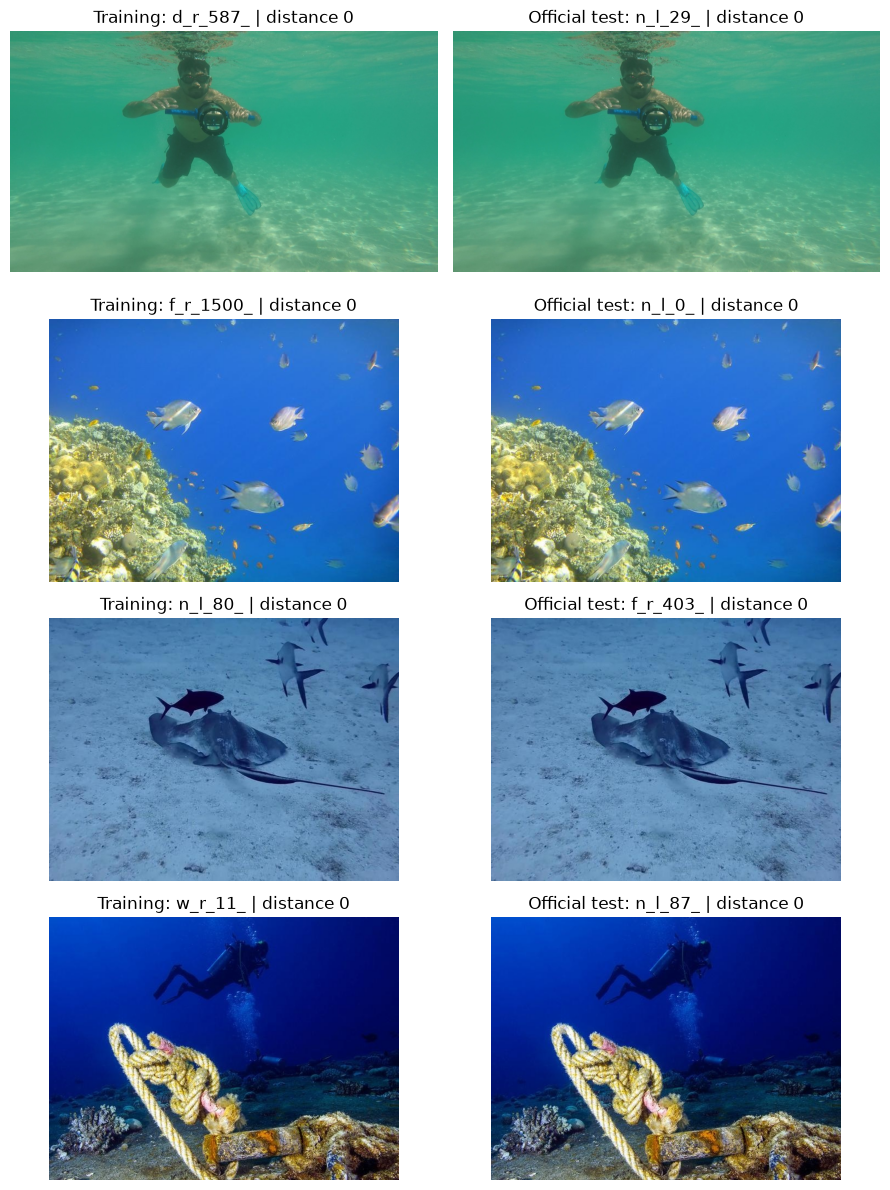

In [12]:
candidates = near_matches_df.head(4)
if len(candidates):
    fig, ax = plt.subplots(len(candidates), 2, figsize=(9, 3 * len(candidates)), squeeze=False)
    test_images = inventories["test"][0]
    for i, pair in enumerate(candidates.itertuples()):
        for j, (path, title) in enumerate(((train_images[pair.train_stem], "Training"), (test_images[pair.test_stem], "Official test"))):
            with Image.open(path) as im: ax[i, j].imshow(im.convert("RGB"))
            ax[i, j].set_title(f"{title}: {path.stem} | distance {pair.hamming_distance}")
            ax[i, j].axis("off")
    plt.tight_layout(); save_fig("near_duplicate_review.png"); plt.show()
else:
    print("No candidates under this screening threshold.")


### Findings and Interpretation

Exact file hashing cannot identify every repeated image. Two images may show the same scene but have different file hashes because of resizing, compression, or minor image modifications.

To investigate this possibility, I used **difference hashing (dHash)** to compare the visual structure of training and test images.

Using a Hamming distance threshold of 5, the analysis identified 18 candidate training-test pairs. Nine pairs had identical difference hashes, corresponding to a Hamming distance of 0.

These findings suggest that additional visually similar images may exist across the dataset splits.

However, a matching or similar perceptual hash does not prove that two images are duplicates. Underwater images can share similar colors, lighting conditions, and scene structures.

I therefore treat these results as candidates for manual inspection rather than automatically excluding them.

The current cleaning policy removes confirmed byte-identical overlaps. The remaining near-duplicate candidates require further investigation before I can determine whether additional exclusions are necessary.


## 8. Construct a transparent cleaning audit

I use the existing rules as a starting point: exclude exact train-test overlaps, mismatched dimensions, invalid palette masks, and problematic duplicates. To make the audit interpretable, I record **all applicable reasons** for each image, plus one primary reason according to a documented priority. The original dataset stays unchanged.

In [13]:
test_hashes = set(hashes_df.loc[hashes_df.split == "test", "sha256"])
train_hashes = hashes_df.loc[hashes_df.split == "train"].set_index("stem")["sha256"].to_dict()
train_dim_ok = dimensions.loc[dimensions.split == "train"].set_index("stem")["size_match"].to_dict()
train_palette_ok = palette_df.loc[palette_df.split == "train"].set_index("stem")["palette_valid"].to_dict()
reasons = {stem: [] for stem in train_stems}
for stem in train_stems:
    if train_hashes[stem] in test_hashes: reasons[stem].append("image identical to a TEST image")
    if not train_dim_ok[stem]: reasons[stem].append("mask size differs from image")
    if not train_palette_ok[stem]: reasons[stem].append("mask has off-code pixel values")

# Duplicate resolution follows the earlier script's logic on otherwise eligible samples.
remaining_groups = defaultdict(list)
for stem in train_stems:
    if not reasons[stem]: remaining_groups[train_hashes[stem]].append(stem)
for digest, members in remaining_groups.items():
    if len(members) < 2: continue
    decoded = []
    for stem in members:
        with Image.open(train_masks[stem]) as im: decoded.append(rgb_to_ids(np.asarray(im.convert("RGB"))))
    # Compare all pairs, not just against the first sample.
    min_agree = min(float((decoded[i] == decoded[j]).mean()) for i in range(len(decoded)) for j in range(i+1, len(decoded)))
    if min_agree < AGREE_MIN:
        for stem in members: reasons[stem].append("duplicate image with conflicting masks")
    else:
        for stem in members[1:]: reasons[stem].append("duplicate image, other copy kept")

priority = ["image identical to a TEST image", "mask size differs from image", "mask has off-code pixel values",
            "duplicate image with conflicting masks", "duplicate image, other copy kept"]
audit = pd.DataFrame([dict(stem=stem, excluded=bool(reasons[stem]),
                           primary_reason=next((r for r in priority if r in reasons[stem]), "kept"),
                           all_reasons="; ".join(reasons[stem])) for stem in train_stems])
save_table(audit, "cleaning_audit.csv")
display(audit.primary_reason.value_counts().rename_axis("decision").reset_index(name="count"))
print("Retained:", int((~audit.excluded).sum()), "| Excluded:", int(audit.excluded.sum()))

,decision,count
0,kept,1425
1,mask has off-code pixel values,48
2,mask size differs from image,37
3,"duplicate image, other copy kept",7
4,image identical to a TEST image,4
5,duplicate image with conflicting masks,4


Retained: 1425 | Excluded: 100



### Findings and Interpretation

After applying the cleaning rules, **100 samples were excluded** from the original 1,525 training and validation image-mask pairs, leaving 1,425 samples.

The exclusions were:

| Primary Exclusion Reason | Samples |
|---|---:|
| Invalid mask colors | 48 |
| Image-mask dimension mismatch | 37 |
| Additional copies of duplicate images | 7 |
| Images identical to official test images | 4 |
| Duplicate images with conflicting masks | 4 |
| **Total Excluded** | **100** |

Each excluded image was assigned one primary reason according to the cleaning priority. Some samples had multiple quality problems, so these counts should not be interpreted as independent totals for every detected issue.

The cleaning process retained approximately **93.4%** of the original training and validation dataset.

I chose to prioritize annotation consistency and leakage prevention rather than retain every available image.

The original dataset files remain unchanged. All cleaning decisions are documented in a separate audit file, allowing the process to be reviewed and reproduced.


## 9. Compare with the preliminary manifest and exclusions

The existing CSVs provide a useful reproducibility check, but they are not the ground truth. I compare both the counts and individual stems. A difference may reflect a changed duplicate rule, an altered file, or a bug that needs investigation.

In [14]:
old_manifest_path = PROJECT_ROOT / "results" / "tables" / "manifest.csv"
old_exclusions_path = PROJECT_ROOT / "results" / "tables" / "exclusions.csv"
if old_manifest_path.exists() and old_exclusions_path.exists():
    old_manifest = pd.read_csv(old_manifest_path)
    old_exclusions = pd.read_csv(old_exclusions_path)
    old_set = set(old_exclusions.stem)
    new_set = set(audit.loc[audit.excluded, "stem"])
    print("Previous split counts:", old_manifest.split.value_counts().to_dict())
    print("Previous exclusions:", len(old_exclusions))
    print("New exclusions:", len(new_set))
    print("Only in old exclusions:", sorted(old_set - new_set)[:20])
    print("Only in new exclusions:", sorted(new_set - old_set)[:20])
    old_reason = old_exclusions.set_index("stem")["reason"].to_dict()
    changes = audit.loc[audit.stem.isin(old_set & new_set)].copy()
    changes["previous_reason"] = changes.stem.map(old_reason)
    changes = changes.loc[changes.primary_reason != changes.previous_reason]
    display(changes.head(20))
else:
    print("Previous CSVs not found at results/tables/. The new audit is still available.")

Previous split counts: {'train': 1211, 'val': 214, 'test': 110}
Previous exclusions: 100
New exclusions: 100
Only in old exclusions: []
Only in new exclusions: []


,stem,excluded,primary_reason,all_reasons,previous_reason



### Findings and Interpretation

I compared the newly generated cleaning audit with the preliminary manifest and exclusion files created during the earlier investigation.

Both analyses excluded exactly 100 samples. There were no differences in the excluded image filenames or their assigned primary exclusion reasons.

The previous manifest also contained 1,211 training samples, 214 validation samples, and 110 official test samples.

This agreement provides additional confidence that the cleaning procedure is reproducible and that the current implementation follows the previously established rules.

However, reproducing the same exclusions does not independently prove that every cleaning decision is optimal. The remaining near-duplicate candidates and other annotation limitations still need to be considered.


## 10. Reproduce the baseline train and validation splits

I split only the retained training pool. I use seed 42 and reserve 15% for validation, matching the previous protocol. The official test set is added to the manifest without any cleaning or repartitioning. I also check that no exact image hashes overlap across splits.

In [15]:
kept = audit.loc[~audit.excluded, "stem"].tolist()
random.Random(SEED).shuffle(kept)
n_val = round(len(kept) * VAL_FRACTION)
val_stems, candidate_training_stems = kept[:n_val], kept[n_val:]
test_stems = inventories["test"][2]
candidate_manifest = pd.DataFrame([{"split": "train", "stem": s} for s in candidate_training_stems] +
                        [{"split": "val", "stem": s} for s in val_stems] +
                        [{"split": "test", "stem": s} for s in test_stems])
save_table(candidate_manifest, "manifest_candidate.csv")
candidate_exclusions = audit.loc[audit.excluded, ["stem", "primary_reason"]].rename(columns={"primary_reason": "reason"})
save_table(candidate_exclusions, "exclusions_candidate.csv")
display(candidate_manifest.split.value_counts().rename_axis("split").reset_index(name="samples"))
assert not candidate_manifest.duplicated(["split", "stem"]).any(), "Duplicate entries within a split."
assert not (set(candidate_training_stems) & set(val_stems)), "Training and validation stems overlap."
test_hash_by_stem = hashes_df.loc[hashes_df.split == "test"].set_index("stem")["sha256"].to_dict()
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    ha = {train_hashes[s] if a != "test" else test_hash_by_stem[s] for s in candidate_manifest.loc[candidate_manifest.split == a, "stem"]}
    hb = {train_hashes[s] if b != "test" else test_hash_by_stem[s] for s in candidate_manifest.loc[candidate_manifest.split == b, "stem"]}
    print(f"Exact hash overlap {a}/{b}:", len(ha & hb))
    assert not ha & hb, f"Exact image leakage detected between {a} and {b}."

,split,samples
0,train,1211
1,val,214
2,test,110


Exact hash overlap train/val: 0
Exact hash overlap train/test: 0
Exact hash overlap val/test: 0



### Findings and Interpretation

After cleaning, I divided the 1,425 retained samples into training and validation subsets using a fixed random seed of 42.

The resulting split contains:

- **1,211 training images**
- **214 validation images**
- **110 official test images**

The validation set represents approximately 15% of the retained training pool.

The training set will be used to optimize the U-Net model, while the validation set will support model selection and monitoring during training.

I use official test images to screen for overlap. I reserve test labels for benchmark evaluation, except for the file and mask integrity checks documented above.

I also verified that no exact image hashes were shared between the training, validation, and official test splits.

This confirms that the candidate splits contain no byte-identical image overlap. However, exact hash checks cannot rule out every visually similar or related scene, so possible near-duplicate leakage remains an area for further review.



## 11. Further Investigation of Near-Duplicate Images

### Objective

The initial data exploration identified 18 candidate image pairs shared between the training and official test datasets using difference hashing (dHash).

Although exact duplicates were already excluded, visually similar images may still represent the same underwater scene.

In this section, I investigate these candidate pairs more carefully to determine whether they represent actual duplicates, modified versions of the same image, or unrelated images with similar visual features.

### Why This Matters

If a training image is nearly identical to a test image, the U-Net model may have already encountered the same scene during training.

This could produce overly optimistic segmentation results and make it difficult to determine whether image enhancement genuinely improves the model's ability to generalize.

I will examine the candidate pairs visually and compare their image similarity before deciding whether additional training samples should be excluded.

The official test set will remain unchanged.


In [16]:
candidate_df = near_matches_df.sort_values(
    ["hamming_distance", "train_stem", "test_stem"]
).reset_index(drop=True)
assert len(candidate_df) == 18, "The review candidate count differs from the documented run."
print("Candidate near-duplicate pairs:", len(candidate_df))
display(candidate_df)

Candidate near-duplicate pairs: 18


,train_stem,test_stem,hamming_distance
0,d_r_587_,n_l_29_,0
1,f_r_1500_,n_l_0_,0
2,f_r_1827_,f_r_1892_,0
3,f_r_2033_,n_l_102_,0
4,f_r_615_,n_l_79_,0
5,n_l_106_,d_r_386_,0
6,n_l_80_,f_r_403_,0
7,w_r_11_,n_l_87_,0
8,w_r_32_,n_l_26_,0
9,f_r_953_,n_l_100_,1


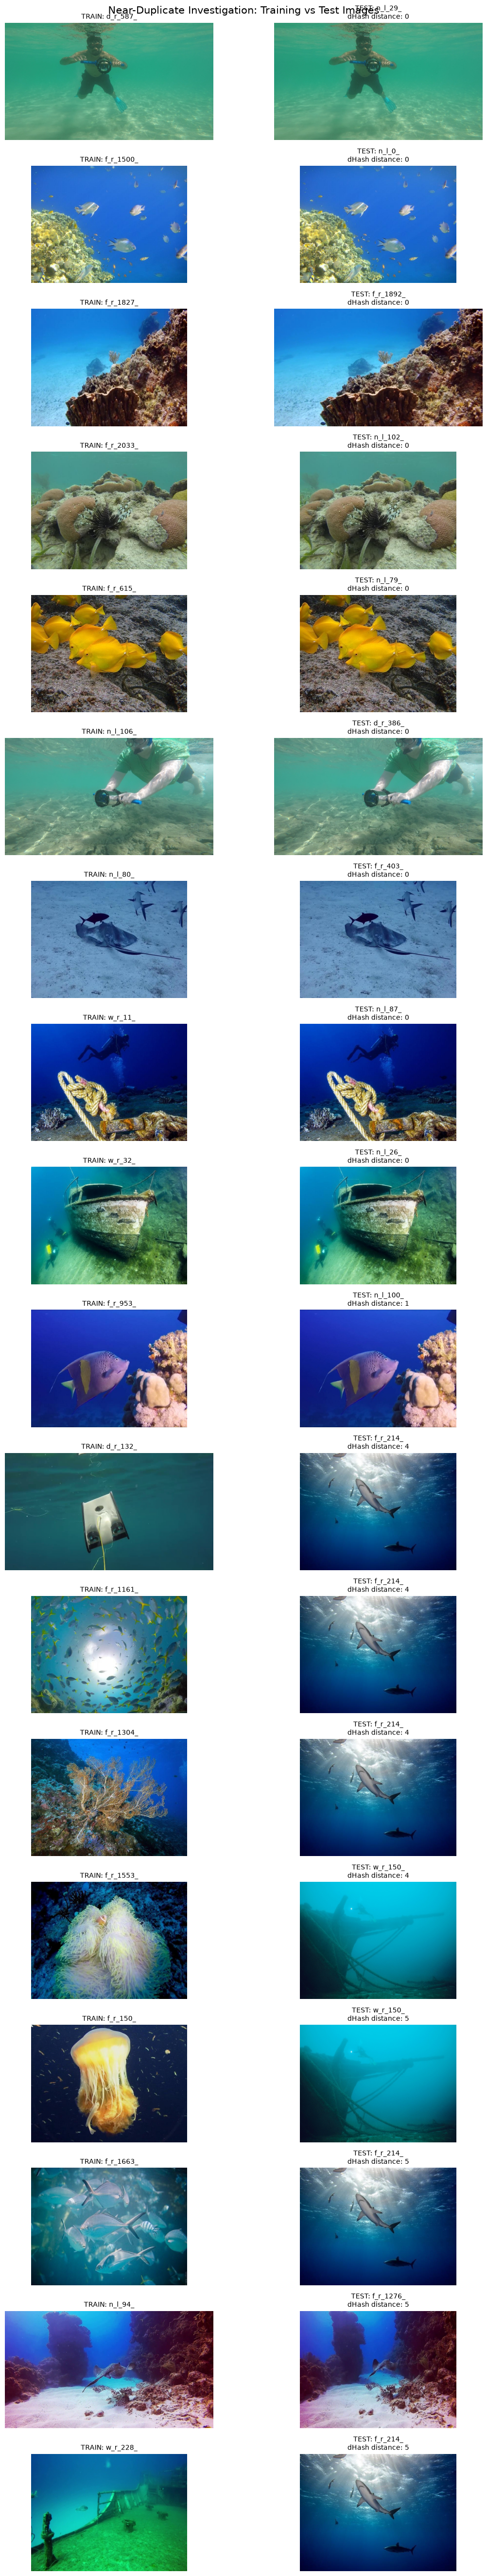

In [17]:
fig, axes = plt.subplots(
    len(candidate_df), 2, figsize=(12, len(candidate_df) * 3), squeeze=False
)
test_images = inventories["test"][0]
for i, row in enumerate(candidate_df.itertuples(index=False)):
    with Image.open(train_images[row.train_stem]) as image:
        axes[i, 0].imshow(image.convert("RGB"))
    with Image.open(test_images[row.test_stem]) as image:
        axes[i, 1].imshow(image.convert("RGB"))
    axes[i, 0].set_title(f"TRAIN: {row.train_stem}", fontsize=10)
    axes[i, 1].set_title(
        f"TEST: {row.test_stem}\ndHash distance: {row.hamming_distance}", fontsize=10
    )
    for axis in axes[i]:
        axis.axis("off")

fig.suptitle("Near-Duplicate Investigation: Training vs Test Images", fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.99))
save_fig("near_duplicate_visual_review.png")
plt.show()


### Interpretation of Near-Duplicate Investigation

The visual review of the 18 training-test candidate pairs identified 11 pairs that appear to depict the same underwater scene. These include nine pairs with identical dHash fingerprints, one pair with a Hamming distance of 1, and one pair with a distance of 5.

The remaining seven pairs appear to depict different scenes despite having similar perceptual hashes. This demonstrates that dHash similarity alone is not sufficient to establish whether two underwater images are duplicates.

These findings are important because repeated scenes across training and test datasets could introduce data leakage and produce overly optimistic segmentation performance.

I will check whether the 11 flagged training images are already excluded by the existing cleaning rules before making further changes. Any additional exclusions will be applied only to the training and validation pool. The official test set will remain unchanged.


In [18]:

# Check flagged near-duplicates against the current cleaned dataset

flagged_train_stems = [
    "d_r_587_",
    "f_r_1500_",
    "f_r_1827_",
    "f_r_2033_",
    "f_r_615_",
    "n_l_106_",
    "n_l_80_",
    "w_r_11_",
    "w_r_32_",
    "f_r_953_",
    "n_l_94_",
]

print("Flagged training images:", len(flagged_train_stems))

# Show the flagged image names for checking against the manifest
display(
    pd.DataFrame({
        "train_stem": flagged_train_stems
    })
)


Flagged training images: 11


,train_stem
0,d_r_587_
1,f_r_1500_
2,f_r_1827_
3,f_r_2033_
4,f_r_615_
5,n_l_106_
6,n_l_80_
7,w_r_11_
8,w_r_32_
9,f_r_953_


In [19]:

# Check whether flagged near-duplicate images remain in the cleaned dataset

flagged_status = pd.DataFrame({
    "stem": flagged_train_stems
})

# Check whether each image appears in the current manifest
flagged_status["in_manifest"] = flagged_status["stem"].isin(
    candidate_manifest.loc[
        candidate_manifest["split"].isin(["train", "val"]),
        "stem"
    ]
)

# Check whether each image was previously excluded
flagged_status["already_excluded"] = flagged_status["stem"].isin(
    candidate_exclusions["stem"]
)

# Retrieve existing exclusion reasons
flagged_status = flagged_status.merge(
    candidate_exclusions[["stem", "reason"]],
    on="stem",
    how="left"
)

flagged_status["status"] = flagged_status.apply(
    lambda row: (
        "Already excluded"
        if row["already_excluded"]
        else "Still retained"
        if row["in_manifest"]
        else "Not found in train/val manifest"
    ),
    axis=1
)

display(flagged_status)

print("\nSummary:")
print(flagged_status["status"].value_counts())


,stem,in_manifest,already_excluded,reason,status
0,d_r_587_,False,True,image identical to a TEST image,Already excluded
1,f_r_1500_,False,True,image identical to a TEST image,Already excluded
2,f_r_1827_,True,False,NaN,Still retained
3,f_r_2033_,True,False,NaN,Still retained
4,f_r_615_,True,False,NaN,Still retained
5,n_l_106_,False,True,image identical to a TEST image,Already excluded
6,n_l_80_,True,False,NaN,Still retained
7,w_r_11_,False,True,image identical to a TEST image,Already excluded
8,w_r_32_,True,False,NaN,Still retained
9,f_r_953_,True,False,NaN,Still retained



Summary:
status
Still retained      7
Already excluded    4
Name: count, dtype: int64


In [20]:
# Fixed decisions from the visual review, keyed by the original training filename stem.
reviewed_exclusions = {
    "f_r_1827_", "f_r_2033_", "f_r_615_", "f_r_953_",
    "n_l_80_", "n_l_94_", "w_r_32_",
}
near_duplicate_reason = "visually confirmed near-duplicate of a TEST image"
assert len(flagged_train_stems) == len(set(flagged_train_stems)) == 11
assert set(flagged_train_stems) <= set(candidate_df["train_stem"])
expected_exact = set(flagged_train_stems) - reviewed_exclusions
already_excluded = flagged_status.loc[flagged_status["already_excluded"]]
assert set(already_excluded["stem"]) == expected_exact
assert already_excluded["reason"].eq("image identical to a TEST image").all()
assert set(flagged_status.loc[flagged_status["in_manifest"], "stem"]) == reviewed_exclusions

affected_rows = candidate_manifest.loc[
    candidate_manifest["split"].ne("test")
    & candidate_manifest["stem"].isin(reviewed_exclusions)
]
assert len(affected_rows) == len(reviewed_exclusions) == 7
assert affected_rows["split"].eq("train").all()
proposed_exclusions = pd.DataFrame({
    "stem": sorted(reviewed_exclusions),
    "reason": near_duplicate_reason,
})
display(affected_rows.sort_values("stem"))
display(proposed_exclusions)

,split,stem
674,train,f_r_1827_
742,train,f_r_2033_
40,train,f_r_615_
807,train,f_r_953_
251,train,n_l_80_
982,train,n_l_94_
856,train,w_r_32_


,stem,reason
0,f_r_1827_,visually confirmed near-duplicate of a TEST image
1,f_r_2033_,visually confirmed near-duplicate of a TEST image
2,f_r_615_,visually confirmed near-duplicate of a TEST image
3,f_r_953_,visually confirmed near-duplicate of a TEST image
4,n_l_80_,visually confirmed near-duplicate of a TEST image
5,n_l_94_,visually confirmed near-duplicate of a TEST image
6,w_r_32_,visually confirmed near-duplicate of a TEST image


In [21]:
# Start from the baseline each time so this cell can be rerun safely.
manifest = candidate_manifest.drop(index=affected_rows.index).reset_index(drop=True)
final_audit = audit.copy()
reviewed = final_audit["stem"].isin(reviewed_exclusions)
assert final_audit.loc[reviewed, "primary_reason"].eq("kept").all()
final_audit.loc[reviewed, "excluded"] = True
final_audit.loc[reviewed, ["primary_reason", "all_reasons"]] = near_duplicate_reason
exclusions = final_audit.loc[final_audit["excluded"], ["stem", "primary_reason"]].rename(
    columns={"primary_reason": "reason"}
).reset_index(drop=True)

split_counts = manifest["split"].value_counts()
reason_counts = exclusions["reason"].value_counts()
assert split_counts.to_dict() == {"train": 1204, "val": 214, "test": 110}
assert len(exclusions) == 107 and exclusions["stem"].is_unique
assert reason_counts.to_dict() == {
    "mask has off-code pixel values": 48,
    "mask size differs from image": 37,
    "duplicate image, other copy kept": 7,
    near_duplicate_reason: 7,
    "image identical to a TEST image": 4,
    "duplicate image with conflicting masks": 4,
}
pd.testing.assert_frame_equal(
    manifest.loc[manifest["split"].ne("train")].reset_index(drop=True),
    candidate_manifest.loc[candidate_manifest["split"].ne("train")].reset_index(drop=True),
)
assert not manifest.duplicated(["split", "stem"]).any()
retained = set(manifest.loc[manifest["split"].ne("test"), "stem"])
assert not retained.intersection(exclusions["stem"])
assert retained.union(exclusions["stem"]) == set(train_stems)

training_stems = manifest.loc[manifest["split"].eq("train"), "stem"].tolist()
save_table(manifest, "manifest.csv")
save_table(exclusions, "exclusions.csv")
save_table(final_audit, "cleaning_audit_final.csv")
display(split_counts.rename_axis("split").reset_index(name="images"))
display(reason_counts.rename_axis("reason").reset_index(name="images"))
print("Final manifest, exclusions, and cleaning audit saved to", TABLE_DIR)

,split,images
0,train,1204
1,val,214
2,test,110


,reason,images
0,mask has off-code pixel values,48
1,mask size differs from image,37
2,"duplicate image, other copy kept",7
3,visually confirmed near-duplicate of a TEST image,7
4,image identical to a TEST image,4
5,duplicate image with conflicting masks,4


Final manifest, exclusions, and cleaning audit saved to C:\Users\sabin\underwater-robotic-segmentation\results\tables\notebook_01



### Final Cleaning Decision After Near-Duplicate Review

The near-duplicate investigation identified **18 candidate pairs** between the original training pool and the official test set using perceptual hashing (dHash).

After visually inspecting these pairs, I identified **11 pairs that appeared to depict the same underwater scenes**. Of these, **four training images had already been excluded** because they were identical to images in the official test set.

The remaining **seven images were still present in the training split**. I excluded these images to **reduce the risk of data leakage**, which could otherwise lead to overly optimistic segmentation performance.

Following this additional cleaning, the total number of excluded training images increased from **100 to 107**. The final dataset contains:

- **1,204 training images**
- **214 validation images**
- **110 official test images**

The exclusion audit now records **48 images with invalid mask colors**, **37 with image-mask dimension mismatches**, **7 redundant duplicate copies**, **7 visually identified near-duplicates of test images**, **4 exact training-test duplicates**, and **4 duplicate images with conflicting masks**.

I retained the existing validation assignments rather than generating a new random split. This maintains consistency with the earlier preprocessing decisions while removing the identified training-test overlaps.

Importantly, **the official test set remains unchanged**, ensuring that all enhancement methods will be evaluated using the same **110 test images**.

Although this additional cleaning improves the reliability of the experiment, **it does not guarantee that every possible near-duplicate has been detected**. I will acknowledge this limitation when interpreting the final segmentation results.

The final files are `manifest.csv`, `exclusions.csv`, and `cleaning_audit_final.csv` under `results/tables/notebook_01/`. The candidate files record the baseline before the visual review.

## 12. Examine class distribution on retained training labels

Class imbalance matters because a model can obtain high pixel accuracy by predicting common classes while missing rare objects. I calculate class pixel counts on the **1,204 final training images**, using valid original masks. I also count how many images contain each class.

,class_id,class_code,class_name,pixels,pixel_fraction,training_images_containing_class
0,0,BW,Water/background,138046974,0.316874,1005
1,1,HD,Diver,10453726,0.023996,303
2,2,PF,Plant,9801369,0.022498,185
3,3,WR,Wreck,30235186,0.069402,211
4,4,RO,Robot,2218338,0.005092,69
5,5,RI,Reef,154411983,0.354439,814
6,6,FV,Fish,31091395,0.071368,803
7,7,SR,Sea floor,59392933,0.136331,474


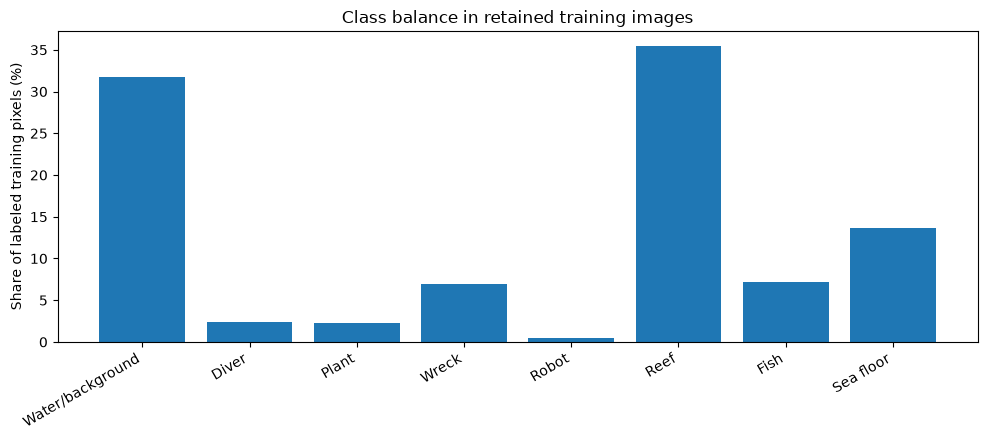

In [22]:
pixel_counts = np.zeros(8, dtype=np.int64)
image_counts = np.zeros(8, dtype=np.int64)
for stem in training_stems:
    with Image.open(train_masks[stem]) as im: mask = rgb_to_ids(np.asarray(im.convert("RGB")))
    counts = np.bincount(mask.ravel(), minlength=8)
    pixel_counts += counts
    image_counts += (counts > 0)
class_df = pd.DataFrame({"class_id": range(8), "class_code": CLASS_CODES, "class_name": CLASS_NAMES,
                         "pixels": pixel_counts, "pixel_fraction": pixel_counts / max(pixel_counts.sum(), 1),
                         "training_images_containing_class": image_counts})
save_table(class_df, "training_class_distribution.csv")
display(class_df)
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(class_df.class_name, class_df.pixel_fraction * 100)
ax.set_ylabel("Share of labeled training pixels (%)")
ax.set_title("Class balance in retained training images")
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
save_fig("class_distribution.png"); plt.show()

### Findings and interpretation

In the **1,204 final training images**, **Reef** and **Water/background** account for **35.44%** and **31.69%** of labeled pixels, respectively. **Robot** has the smallest pixel share (**0.51%**) and occurs in **69 training images**. I will report **mean intersection over union (mIoU)**, **per-class IoU**, and **pixel accuracy** when evaluating the U-Net. Per-class IoU will help show whether an enhancement method affects uncommon classes differently from classes that account for a large share of labeled pixels.

I will start with the observed class distribution and document any later loss or sampling changes.

## 13. Verify resizing choices without changing original files

The planned U-Net input size is 256 × 256. Bicubic interpolation is appropriate for continuous RGB image intensities, while nearest-neighbor interpolation preserves discrete segmentation class IDs. I verify this behavior on the first image in the final training split. Resizing does not fix incorrect original mask alignment.

Final training example: f_r_594_
Image size: (640, 480) -> (256, 256)
Mask IDs before: [0, 2, 5, 6]
Mask IDs after: [0, 2, 5, 6]


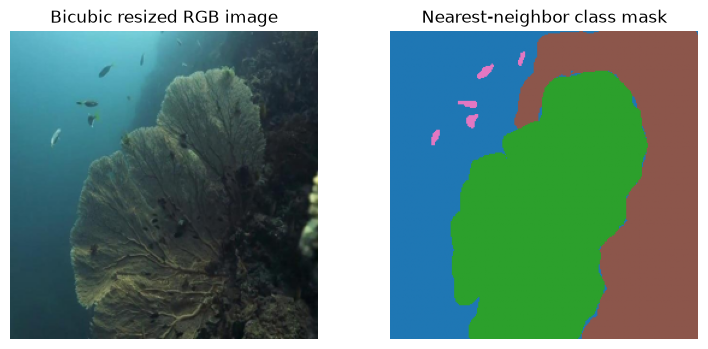

In [23]:
assert training_stems, "No clean training samples remain. Review the audit."
stem = training_stems[0]
with Image.open(train_images[stem]) as im:
    original_image = im.convert("RGB").copy()
with Image.open(train_masks[stem]) as im:
    original_rgb_mask = np.asarray(im.convert("RGB"))
original_ids = rgb_to_ids(original_rgb_mask)
resized_image = original_image.resize((256, 256), Image.Resampling.BICUBIC)
resized_mask = Image.fromarray(original_ids).resize((256, 256), Image.Resampling.NEAREST)
print("Final training example:", stem)
print("Image size:", original_image.size, "->", resized_image.size)
print("Mask IDs before:", np.unique(original_ids).tolist())
print("Mask IDs after:", np.unique(np.asarray(resized_mask)).tolist())
assert set(np.unique(np.asarray(resized_mask))).issubset(set(np.unique(original_ids)))
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(resized_image); ax[0].set_title("Bicubic resized RGB image")
ax[1].imshow(np.asarray(resized_mask), cmap="tab10", vmin=0, vmax=9); ax[1].set_title("Nearest-neighbor class mask")
for a in ax: a.axis("off")
save_fig("resize_verification.png"); plt.show()

### Findings and interpretation

The final training example `f_r_594_` was resized from **640 × 480** to **256 × 256**. The class IDs were `[0, 2, 5, 6]` before resizing and `[0, 2, 5, 6]` afterward. **Nearest-neighbor interpolation** preserves discrete label values and may remove small regions during downsampling. **Bicubic interpolation** is used for the RGB image.

Resizing a non-square image to **256 × 256** changes its aspect ratio and may distort object shapes. I will apply the same resizing procedure in the RAW, CLAHE, and FUnIE-GAN conditions.

## 14. Research decisions and limitations

- **Annotation quality.** Excluding mismatched masks and off-palette labels improves consistency under the chosen checks. Valid sizes and colors still allow semantic annotation errors. The training distribution may also shift if excluded samples represent particular classes or scenes.
- **Exact duplicate handling.** Byte hashes detect identical files. The **90%** pixel-agreement threshold for training duplicate masks was a study decision based on the decoded labels.
- **Near-duplicate review.** I used test images to identify potential overlaps and excluded **seven additional training images** based on the documented visual review. dHash at distance **≤ 5** and visual judgments can miss related frames or scenes. The random validation split can also contain related scenes.
- **Benchmark and preprocessing.** All **110 official test pairs** remain in the benchmark. Test labels were inspected for data integrity and are reserved for final scoring when evaluating models. Resizing to 256 × 256 can alter shapes and reduce the visibility of small objects.

## 15. where this leaves me

I started with **1,525 training and validation pairs** and **110 official test pairs**. The quality audit and visual overlap review yielded **107 exclusions**, including **seven visually reviewed near-duplicates** of test images. The final manifest contains **1,204 training, 214 validation, and 110 official test images**. The class and resize checks describe the final training split.

In **Notebook 02: U-Net Architecture and Training**, I will train a U-Net on the original underwater images using the final manifest and select the model using the established validation split. I will then freeze the selected model and compare **RAW**, **CLAHE**, and **FUnIE-GAN** on the same official test images and labels. That comparison will test whether enhancement changes segmentation performance as measured by mIoU, per-class IoU, and pixel accuracy.